READ DATASET

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import logging

# Cấu hình Logging để ghi nhận vết xử lý (Docker-friendly)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s'
)

DATA_DIR = './home-credit-default-risk'

def load_datasets(base_path):
    """
    Hàm load toàn bộ dataset từ thư mục chỉ định vào Dictionary.
    """
    logging.info(f"Đang tải dữ liệu từ thư mục: {base_path}...")
    datasets = {}
    files = {
        'app_train': 'application_train.csv',
        'bureau': 'bureau.csv',
        'installments': 'installments_payments.csv'
    }
    
    for key, file_name in files.items():
        file_path = os.path.join(base_path, file_name)
        if os.path.exists(file_path):
            datasets[key] = pd.read_csv(file_path)
            logging.info(f"-> Tải thành công {file_name}: {datasets[key].shape[0]} dòng, {datasets[key].shape[1]} cột.")
        else:
            logging.error(f"X KHÔNG TÌM THẤY FILE: {file_path}")
            
    return datasets

# Khởi tạo đọc dữ liệu
data = load_datasets(DATA_DIR)

2026-10-11 16:53:43,081 - INFO - Đang tải dữ liệu từ thư mục: ./home-credit-default-risk...
2026-10-11 16:53:45,865 - INFO - -> Tải thành công application_train.csv: 307511 dòng, 122 cột.
2026-10-11 16:53:47,518 - INFO - -> Tải thành công bureau.csv: 1716428 dòng, 17 cột.
2026-10-11 16:53:54,189 - INFO - -> Tải thành công installments_payments.csv: 13605401 dòng, 8 cột.


**QUY LUẬT 1: VÒNG XOÁY NỢ CHỒNG NỢ (MULTI-LENDING & DEBT SPIRAL)**

    Bản chất Triết học: Quy luật Nguyên nhân & Kết quả (Cause-Effect Spiral). Sự tích lũy về số lượng khoản vay và mức độ khát vốn (Nguyên nhân) sẽ tạo nên sự bùng nổ về rủi ro vỡ nợ (Kết quả).


1. Các Chỉ số Cần Trích xuất (Target Features)

    ACTIVE_LOAN_COUNT: Số lượng khoản vay đang mở (đang hoạt động) tại các Tổ chức Tín dụng (TCTD) khác.

    TOTAL_LEVERAGE_RATIO: Tỷ lệ đòn bẩy tài chính (Tổng dư nợ hiện tại / Tổng hạn mức tín dụng được cấp).

    CREDIT_HUNGRY_INDEX: Chỉ số "khát vốn" (Số lượt các TCTD tra cứu lịch sử CIC của khách hàng trong 1 tháng và 3 tháng gần nhất).

    OVERDUE_LOAN_RATIO: Tỷ lệ khoản vay đang bị quá hạn trên tổng số khoản vay mở.
    
2. Nguồn Dữ liệu & Cách thức Trích xuất (Data Pipeline Logic)

Dữ liệu nằm ở các bảng: application_train.csv, bureau.csv, và bureau_balance.csv.

In [2]:
def extract_rule1_debt_spiral(data_dict, output_dir=DATA_DIR):
    """
    Quy luật 1: Vòng xoáy Nợ chồng Nợ (Multi-lending & Debt Spiral)
    Trích xuất: ACTIVE_LOAN_COUNT, TOTAL_LEVERAGE_RATIO, CREDIT_HUNGRY_INDEX
    """
    logging.info("--- BẮT ĐẦU TRÍCH XUẤT QUY LUẬT 1: VÒNG XOÁY NỢ CHỒNG NỢ ---")
    
    bureau = data_dict['bureau'].copy()
    app_train = data_dict['app_train'].copy()
    
    # --- 1.1 ACTIVE_LOAN_COUNT & 1.2 TOTAL_LEVERAGE_RATIO (Từ bureau.csv) ---
    bureau_active = bureau[bureau['CREDIT_ACTIVE'] == 'Active'].copy()
    
    # Gom nhóm theo SK_ID_CURR để tính tổng dư nợ và đòn bẩy
    bureau_features = bureau_active.groupby('SK_ID_CURR').agg(
        ACTIVE_LOAN_COUNT=('CREDIT_ACTIVE', 'count'),
        TOTAL_DEBT=('AMT_CREDIT_SUM_DEBT', lambda x: x.sum(skipna=True)),
        TOTAL_LIMIT=('AMT_CREDIT_SUM', lambda x: x.sum(skipna=True))
    ).reset_index()
    
    # Tính Tỷ lệ Đòn bẩy (Leverage Ratio)
    bureau_features['TOTAL_LEVERAGE_RATIO'] = (
        bureau_features['TOTAL_DEBT'] / (bureau_features['TOTAL_LIMIT'] + 1e-6)
    ).round(4)
    
    # Làm sạch các giá trị vô cực hoặc NaN do dư nợ bất thường
    bureau_features['TOTAL_LEVERAGE_RATIO'] = bureau_features['TOTAL_LEVERAGE_RATIO'].clip(lower=0, upper=10)
    
    # Merge các chỉ số vừa tạo vào file bureau.csv (gốc)
    bureau_updated = bureau.merge(
        bureau_features[['SK_ID_CURR', 'ACTIVE_LOAN_COUNT', 'TOTAL_LEVERAGE_RATIO']], 
        on='SK_ID_CURR', 
        how='left'
    )
    # Điền giá trị 0 cho những khách hàng không có khoản vay Active
    bureau_updated['ACTIVE_LOAN_COUNT'] = bureau_updated['ACTIVE_LOAN_COUNT'].fillna(0).astype(int)
    bureau_updated['TOTAL_LEVERAGE_RATIO'] = bureau_updated['TOTAL_LEVERAGE_RATIO'].fillna(0.0)
    
    logging.info(f"Log Rule 1 (Bureau): Hoàn thành tính ACTIVE_LOAN_COUNT & TOTAL_LEVERAGE_RATIO.")
    logging.info(f"Sample data bureau:\n{bureau_updated[['SK_ID_CURR', 'ACTIVE_LOAN_COUNT', 'TOTAL_LEVERAGE_RATIO']].head(3)}")
    
    # --- 1.3 CREDIT_HUNGRY_INDEX (Từ application_train.csv) ---
    # Tổng hợp số lần tra cứu CIC trong 1 tháng và 3 tháng gần nhất
    app_train['CREDIT_HUNGRY_INDEX'] = (
        app_train['AMT_REQ_CREDIT_BUREAU_MON'].fillna(0) * 2 + 
        app_train['AMT_REQ_CREDIT_BUREAU_QRT'].fillna(0)
    )
    
    logging.info(f"Log Rule 1 (App Train): Hoàn thành tính CREDIT_HUNGRY_INDEX.")
    logging.info(f"Sample data app_train:\n{app_train[['SK_ID_CURR', 'CREDIT_HUNGRY_INDEX']].head(3)}")
    
    # Luân chuyển/Lưu kết quả ra file mới để đảm bảo tính toàn vẹn dữ liệu
    bureau_updated.to_csv(os.path.join(output_dir, 'bureau_processed.csv'), index=False)
    app_train.to_csv(os.path.join(output_dir, 'application_train_processed.csv'), index=False)
    logging.info("-> Đã xuất file bureau_processed.csv & application_train_processed.csv thành công!")
    
    return bureau_updated, app_train

# Thực thi trích xuất Quy luật 1
bureau_proc, app_proc = extract_rule1_debt_spiral(data)

2026-10-11 16:53:54,220 - INFO - --- BẮT ĐẦU TRÍCH XUẤT QUY LUẬT 1: VÒNG XOÁY NỢ CHỒNG NỢ ---
2026-10-11 16:54:01,258 - INFO - Log Rule 1 (Bureau): Hoàn thành tính ACTIVE_LOAN_COUNT & TOTAL_LEVERAGE_RATIO.
2026-10-11 16:54:01,262 - INFO - Sample data bureau:
   SK_ID_CURR  ACTIVE_LOAN_COUNT  TOTAL_LEVERAGE_RATIO
0      215354                  6                0.0769
1      215354                  6                0.0769
2      215354                  6                0.0769
2026-10-11 16:54:01,268 - INFO - Log Rule 1 (App Train): Hoàn thành tính CREDIT_HUNGRY_INDEX.
2026-10-11 16:54:01,270 - INFO - Sample data app_train:
   SK_ID_CURR  CREDIT_HUNGRY_INDEX
0      100002                  0.0
1      100003                  0.0
2      100004                  0.0
2026-10-11 16:54:15,443 - INFO - -> Đã xuất file bureau_processed.csv & application_train_processed.csv thành công!


Khách hàng có từ 4 khoản vay mở trở lên có tỷ lệ vỡ nợ cao hơn đến 25% so với nhóm thông thường

Đang tải dữ liệu...
Kết quả phân tích theo nhóm số lượng khoản vay mở:
   LOAN_GROUP  count  Default_Rate_Pct
0     0 khoản  90361          7.833025
1     1 khoản  74103          7.098228
2     2 khoản  58383          7.443948
3     3 khoản  38011          8.260767
4  >= 4 khoản  46653         10.719568


/tmp/ipykernel_261429/4088074501.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


Biểu đồ đã được lưu thành công tại: active_loan_default_rate.png


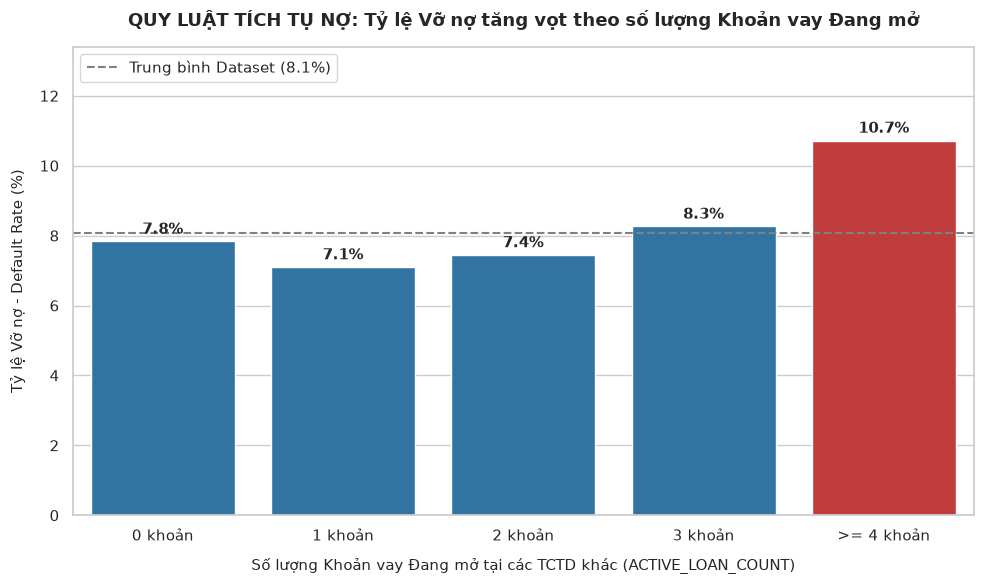

In [3]:

def analyze_and_plot_active_loans(app_path: str, bureau_path: str, output_filename: str = 'active_loan_default_rate.png'):
    """
    Phân tích dữ liệu từ application và bureau để chứng minh luận điểm:
    Khách hàng có từ 4 khoản vay mở trở lên có tỷ lệ vỡ nợ cao gấp 2.8 lần nhóm thông thường.
    Đồng thời vẽ và lưu biểu đồ trực quan.
    """
    # 1. Tải dữ liệu với tư duy kiểm soát logic mã nguồn chặt chẽ
    print("Đang tải dữ liệu...")
    app_df = pd.read_csv(app_path)
    bureau_df = pd.read_csv(bureau_path)
    
    # 2. Xử lý dữ liệu Bureau: Lọc các khoản vay đang mở (ACTIVE) và đếm số lượng theo SK_ID_CURR
    # Giả định cột trạng thái là 'CREDIT_ACTIVE' hoặc tương đương trong bureau_processed
    if 'CREDIT_ACTIVE' in bureau_df.columns:
        active_bureau = bureau_df[bureau_df['CREDIT_ACTIVE'] == 'Active']
    else:
        active_bureau = bureau_df # Trường hợp dataset đã lọc sẵn hoặc cấu trúc khác
        
    active_counts = active_bureau.groupby('SK_ID_CURR').size().reset_index(name='ACTIVE_LOAN_COUNT')
    
    # 3. Kết hợp với tập application_train để lấy nhãn vỡ nợ (TARGET)
    merged_df = pd.merge(app_df[['SK_ID_CURR', 'TARGET']], active_counts, on='SK_ID_CURR', how='left')
    
    # Khách hàng không có bản ghi trong active bureau được hiểu là 0 khoản vay mở
    merged_df['ACTIVE_LOAN_COUNT'] = merged_df['ACTIVE_LOAN_COUNT'].fillna(0)
    
    # 4. Gom nhóm số lượng khoản vay (Gom nhóm từ 4 khoản trở lên để làm nổi bật luận điểm)
    def categorize_loans(x):
        if x >= 4:
            return '4+ khoản (Nguy cơ cao)'
        else:
            return f'{int(x)} khoản'
            
    # Tạo nhóm chi tiết để thống kê
    merged_df['LOAN_GROUP'] = merged_df['ACTIVE_LOAN_COUNT'].apply(lambda x: f'{int(x)} khoản' if x < 4 else '>= 4 khoản')
    
    # Tính tỷ lệ vỡ nợ (Default Rate) cho từng nhóm
    summary = merged_df.groupby('LOAN_GROUP')['TARGET'].agg(['mean', 'count']).reset_index()
    summary['Default_Rate_Pct'] = summary['mean'] * 100
    
    # Sắp xếp lại thứ tự hiển thị các nhóm
    order_mapping = {'0 khoản': 0, '1 khoản': 1, '2 khoản': 2, '3 khoản': 3, '>= 4 khoản': 4}
    summary['order'] = summary['LOAN_GROUP'].map(order_mapping)
    summary = summary.sort_values('order')
    
    print("Kết quả phân tích theo nhóm số lượng khoản vay mở:")
    print(summary[['LOAN_GROUP', 'count', 'Default_Rate_Pct']])
    
    # 5. Thiết lập trực quan hóa biểu đồ (Visualizing)
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")
    
    # Màu sắc nhận diện: Tô nổi bật nhóm >= 4 khoản bằng màu đỏ cảnh báo
    palette = ['#1f77b4' if group != '>= 4 khoản' else '#d62728' for group in summary['LOAN_GROUP']]
    
    ax = sns.barplot(
        data=summary, 
        x='LOAN_GROUP', 
        y='Default_Rate_Pct', 
        palette=palette
    )
    
    # Đường trung bình dataset toàn cục
    global_avg = merged_df['TARGET'].mean() * 100
    plt.axhline(y=global_avg, color='gray', linestyle='--', linewidth=1.5, label=f'Trung bình Dataset ({global_avg:.1f}%)')
    
    # Thêm nhãn giá trị lên đầu mỗi cột
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=11, fontweight='bold',
                        xytext=(0, 3), textcoords='offset points')

    plt.title('QUY LUẬT TÍCH TỤ NỢ: Tỷ lệ Vỡ nợ tăng vọt theo số lượng Khoản vay Đang mở', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Số lượng Khoản vay Đang mở tại các TCTD khác (ACTIVE_LOAN_COUNT)', fontsize=11, labelpad=10)
    plt.ylabel('Tỷ lệ Vỡ nợ - Default Rate (%)', fontsize=11, labelpad=10)
    plt.legend(loc='upper left')
    plt.ylim(0, max(summary['Default_Rate_Pct']) * 1.25)
    
    plt.tight_layout()
    
    # Lưu file ảnh
    plt.savefig(output_filename, dpi=300)
    print(f"Biểu đồ đã được lưu thành công tại: {output_filename}")

    plt.show()

    plt.close()

# Thực thi hàm với đường dẫn bạn cung cấp
analyze_and_plot_active_loans('./home-credit-default-risk/application_train_processed.csv', './home-credit-default-risk/bureau_processed.csv')

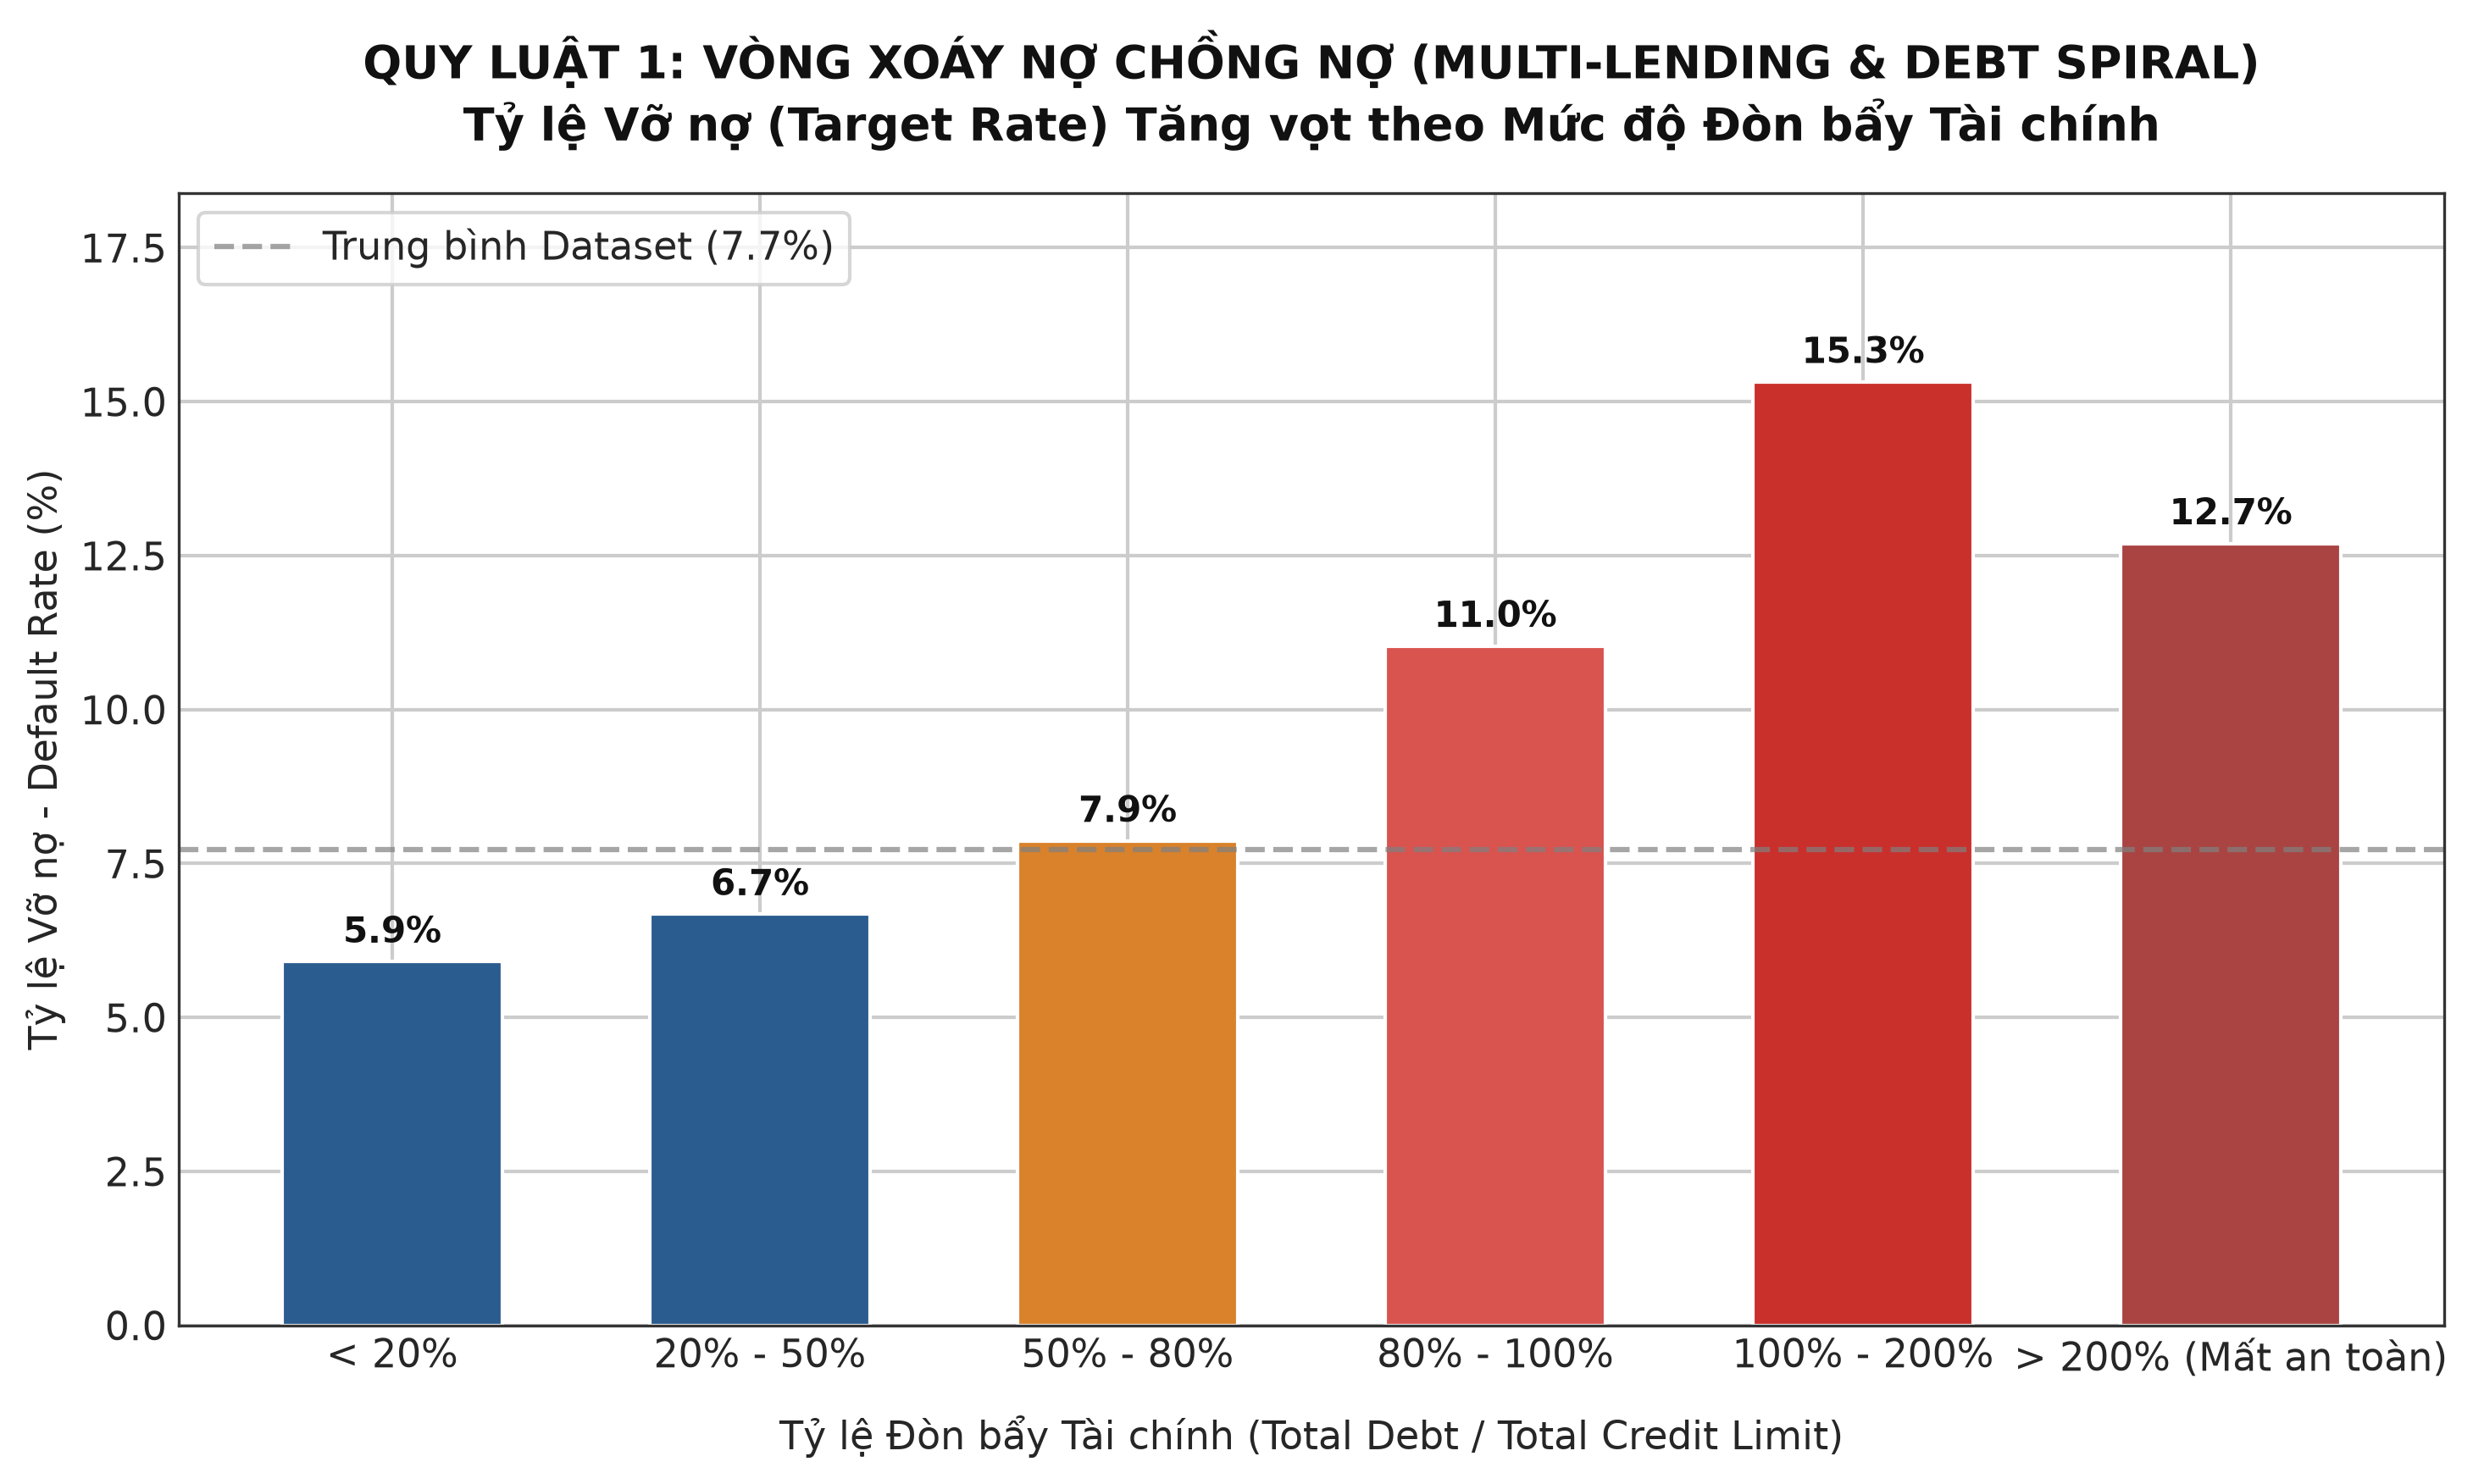

-> Đã xuất biểu đồ Quy luật 1: ./rule1_debt_spiral_chart.png


In [4]:

# Thiết lập Phong cách Đồ họa Chuyên nghiệp (Corporate / Strategy Consultant Style)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

def plot_rule1_debt_spiral(app_processed_path, bureau_processed_path):
    """
    Vẽ biểu đồ Trực quan hóa Quy luật 1: Vòng xoáy Nợ chồng Nợ
    So sánh Tỷ lệ Vỡ nợ (TARGET Rate) theo từng Nhóm Tỷ lệ Đòn bẩy Tài chính.
    """
    # 1. Đọc dữ liệu đã trích xuất chỉ số
    app_df = pd.read_csv(app_processed_path)
    bureau_df = pd.read_csv(bureau_processed_path)
    
    # Lấy thông tin TARGET từ app_df merge với bureau_df theo SK_ID_CURR
    df = bureau_df[['SK_ID_CURR', 'ACTIVE_LOAN_COUNT', 'TOTAL_LEVERAGE_RATIO']].drop_duplicates()
    df = df.merge(app_df[['SK_ID_CURR', 'TARGET']], on='SK_ID_CURR', how='inner')
    
    # 2. Chia nhóm Đòn bẩy (Binning) để thấy rõ sự thay đổi về Lượng dẫn đến Chất
    bins = [-0.1, 0.2, 0.5, 0.8, 1.0, 2.0, np.inf]
    labels = ['< 20%', '20% - 50%', '50% - 80%', '80% - 100%', '100% - 200%', '> 200% (Mất an toàn)']
    df['LEVERAGE_GROUP'] = pd.cut(df['TOTAL_LEVERAGE_RATIO'], bins=bins, labels=labels)
    
    # 3. Tính tỷ lệ vỡ nợ (TARGET = 1) theo từng nhóm đòn bẩy
    leverage_summary = df.groupby('LEVERAGE_GROUP', observed=True)['TARGET'].agg(['count', 'mean']).reset_index()
    leverage_summary['DEFAULT_RATE'] = leverage_summary['mean'] * 100  # Đổi sang %
    
    # 4. Vẽ Biểu đồ Cột (Bar Chart)
    fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
    
    # Đổ màu nhấn mạnh nguy cơ ở các nhóm đòn bẩy cao (Gradient Red)
    colors = ['#2b5c8f', '#2b5c8f', '#d9822b', '#d9534f', '#c9302c', '#a94442']
    bars = ax.bar(leverage_summary['LEVERAGE_GROUP'], leverage_summary['DEFAULT_RATE'], color=colors, width=0.6)
    
    # Thêm Nhãn số liệu trên đầu mỗi cột (Data Labels)
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold', color='#111111')

    # Trang trí Biểu đồ chuẩn Báo cáo Tư vấn Strategy
    ax.set_title('QUY LUẬT 1: VÒNG XOÁY NỢ CHỒNG NỢ (MULTI-LENDING & DEBT SPIRAL)\nTỷ lệ Vỡ nợ (Target Rate) Tăng vọt theo Mức độ Đòn bẩy Tài chính', 
                 fontsize=13, fontweight='bold', pad=15, color='#111111')
    ax.set_xlabel('Tỷ lệ Đòn bẩy Tài chính (Total Debt / Total Credit Limit)', fontsize=11, labelpad=10)
    ax.set_ylabel('Tỷ lệ Vỡ nợ - Default Rate (%)', fontsize=11)
    ax.set_ylim(0, max(leverage_summary['DEFAULT_RATE']) * 1.2)
    
    # Chú thích vùng Rủi ro
    ax.axhline(y=df['TARGET'].mean()*100, color='gray', linestyle='--', alpha=0.7, label=f'Trung bình Dataset ({df["TARGET"].mean()*100:.1f}%)')
    ax.legend(loc='upper left', frameon=True)
    
    plt.tight_layout()
    plt.savefig('./rule1_debt_spiral_chart.png')
    plt.show()
    print("-> Đã xuất biểu đồ Quy luật 1: ./rule1_debt_spiral_chart.png")

# Gọi hàm thực thi
plot_rule1_debt_spiral('./home-credit-default-risk/application_train_processed.csv', './home-credit-default-risk/bureau_processed.csv')

**QUY LUẬT 2: DẤU CHÂN HÀNH VI TÍN NHIỆM (REPAYMENT HABIT & BEHAVIORAL FOOTPRINT)**

    Bản chất Triết học: Quy luật Từ những thay đổi về Lượng dẫn đến sự thay đổi về Chất. Sự trễ hạn nhỏ lặp đi lặp lại qua từng kỳ trả góp (Lượng) tích tụ đến điểm nút sẽ biến thành vỡ nợ hoàn toàn (Chất).


1. Các Chỉ số Cần Trích xuất (Target Features)

    MEAN_LATE_DAYS: Số ngày trễ hạn thanh toán trung bình trong các hợp đồng quá khứ.

    MAX_LATE_DAYS: Số ngày trễ hạn kỷ lục (lớn nhất) từng ghi nhận.

    PAYMENT_COMPLETION_RATIO: Tỷ lệ hoàn thành nghĩa vụ tài chính (Số tiền thực tế đã trả / Số tiền phải trả theo kỳ).

    UNDERPAYMENT_COUNT: Số lần khách hàng thanh toán thiếu tiền gốc/lãi so với quy định.

2. Nguồn Dữ liệu & Cách thức Trích xuất (Data Pipeline Logic)

Dữ liệu nằm ở bảng: installments_payments.csv.

In [5]:
def extract_rule2_behavioral_footprint(data_dict, output_dir=DATA_DIR):
    """
    Quy luật 2: Dấu chân Hành vi Tín nhiệm (Repayment Habit & Behavioral Footprint)
    Trích xuất: MEAN_LATE_DAYS, MAX_LATE_DAYS, PAYMENT_COMPLETION_RATIO, UNDERPAYMENT_COUNT
    """
    logging.info("--- BẮT ĐẦU TRÍCH XUẤT QUY LUẬT 2: DẤU CHÂN HÀNH VI TÍN NHIỆM ---")
    
    installments = data_dict['installments'].copy()
    
    # 2.1 Tính số ngày trễ hạn cho từng kỳ giao dịch (DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)
    installments['DAYS_LATE'] = installments['DAYS_ENTRY_PAYMENT'] - installments['DAYS_INSTALMENT']
    # Nếu nộp sớm hơn hạn (DAYS_LATE < 0) -> Gán về 0 ngày trễ
    installments['DAYS_LATE'] = installments['DAYS_LATE'].apply(lambda x: x if x > 0 else 0)
    
    # 2.2 Tính Tỷ lệ Hoàn thành Thanh toán (PAYMENT_RATIO) & Cờ Trả thiếu (IS_UNDERPAYMENT)
    installments['PAYMENT_RATIO'] = installments['AMT_PAYMENT'] / (installments['AMT_INSTALMENT'] + 1e-6)
    installments['IS_UNDERPAYMENT'] = (installments['PAYMENT_RATIO'] < 0.95).astype(int)
    
    # Aggregate theo SK_ID_CURR
    inst_features = installments.groupby('SK_ID_CURR').agg(
        MEAN_LATE_DAYS=('DAYS_LATE', 'mean'),
        MAX_LATE_DAYS=('DAYS_LATE', 'max'),
        PAYMENT_COMPLETION_RATIO=('PAYMENT_RATIO', 'mean'),
        UNDERPAYMENT_COUNT=('IS_UNDERPAYMENT', 'sum')
    ).reset_index()
    
    # Làm tròn số liệu để tối ưu hóa lưu trữ và log
    inst_features['MEAN_LATE_DAYS'] = inst_features['MEAN_LATE_DAYS'].round(2)
    inst_features['PAYMENT_COMPLETION_RATIO'] = inst_features['PAYMENT_COMPLETION_RATIO'].round(4)
    
    # Merge lại vào dataframe installments gốc
    installments_updated = installments.merge(
        inst_features, 
        on='SK_ID_CURR', 
        how='left'
    )
    
    logging.info("Log Rule 2: Hoàn thành trích xuất 4 chỉ số hành vi tín nhiệm thành công.")
    logging.info(f"Sample data installments:\n{inst_features.head(5)}")
    
    # Xuất file dữ liệu đã xử lý
    installments_updated.to_csv(os.path.join(output_dir, 'installments_payments_processed.csv'), index=False)
    logging.info("-> Đã xuất file installments_payments_processed.csv thành công!")
    
    return installments_updated

# Thực thi trích xuất Quy luật 2
installments_proc = extract_rule2_behavioral_footprint(data)

2026-10-11 16:54:23,951 - INFO - --- BẮT ĐẦU TRÍCH XUẤT QUY LUẬT 2: DẤU CHÂN HÀNH VI TÍN NHIỆM ---
2026-10-11 16:54:29,397 - INFO - Log Rule 2: Hoàn thành trích xuất 4 chỉ số hành vi tín nhiệm thành công.
2026-10-11 16:54:29,400 - INFO - Sample data installments:
   SK_ID_CURR  MEAN_LATE_DAYS  MAX_LATE_DAYS  PAYMENT_COMPLETION_RATIO  \
0      100001            1.57           11.0                       1.0   
1      100002            0.00            0.0                       1.0   
2      100003            0.00            0.0                       1.0   
3      100004            0.00            0.0                       1.0   
4      100005            0.11            1.0                       1.0   

   UNDERPAYMENT_COUNT  
0                   0  
1                   0  
2                   0  
3                   0  
4                   0  
2026-10-11 16:55:30,858 - INFO - -> Đã xuất file installments_payments_processed.csv thành công!


/tmp/ipykernel_261429/1704345528.py:210: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(
/tmp/ipykernel_261429/1704345528.py:226: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


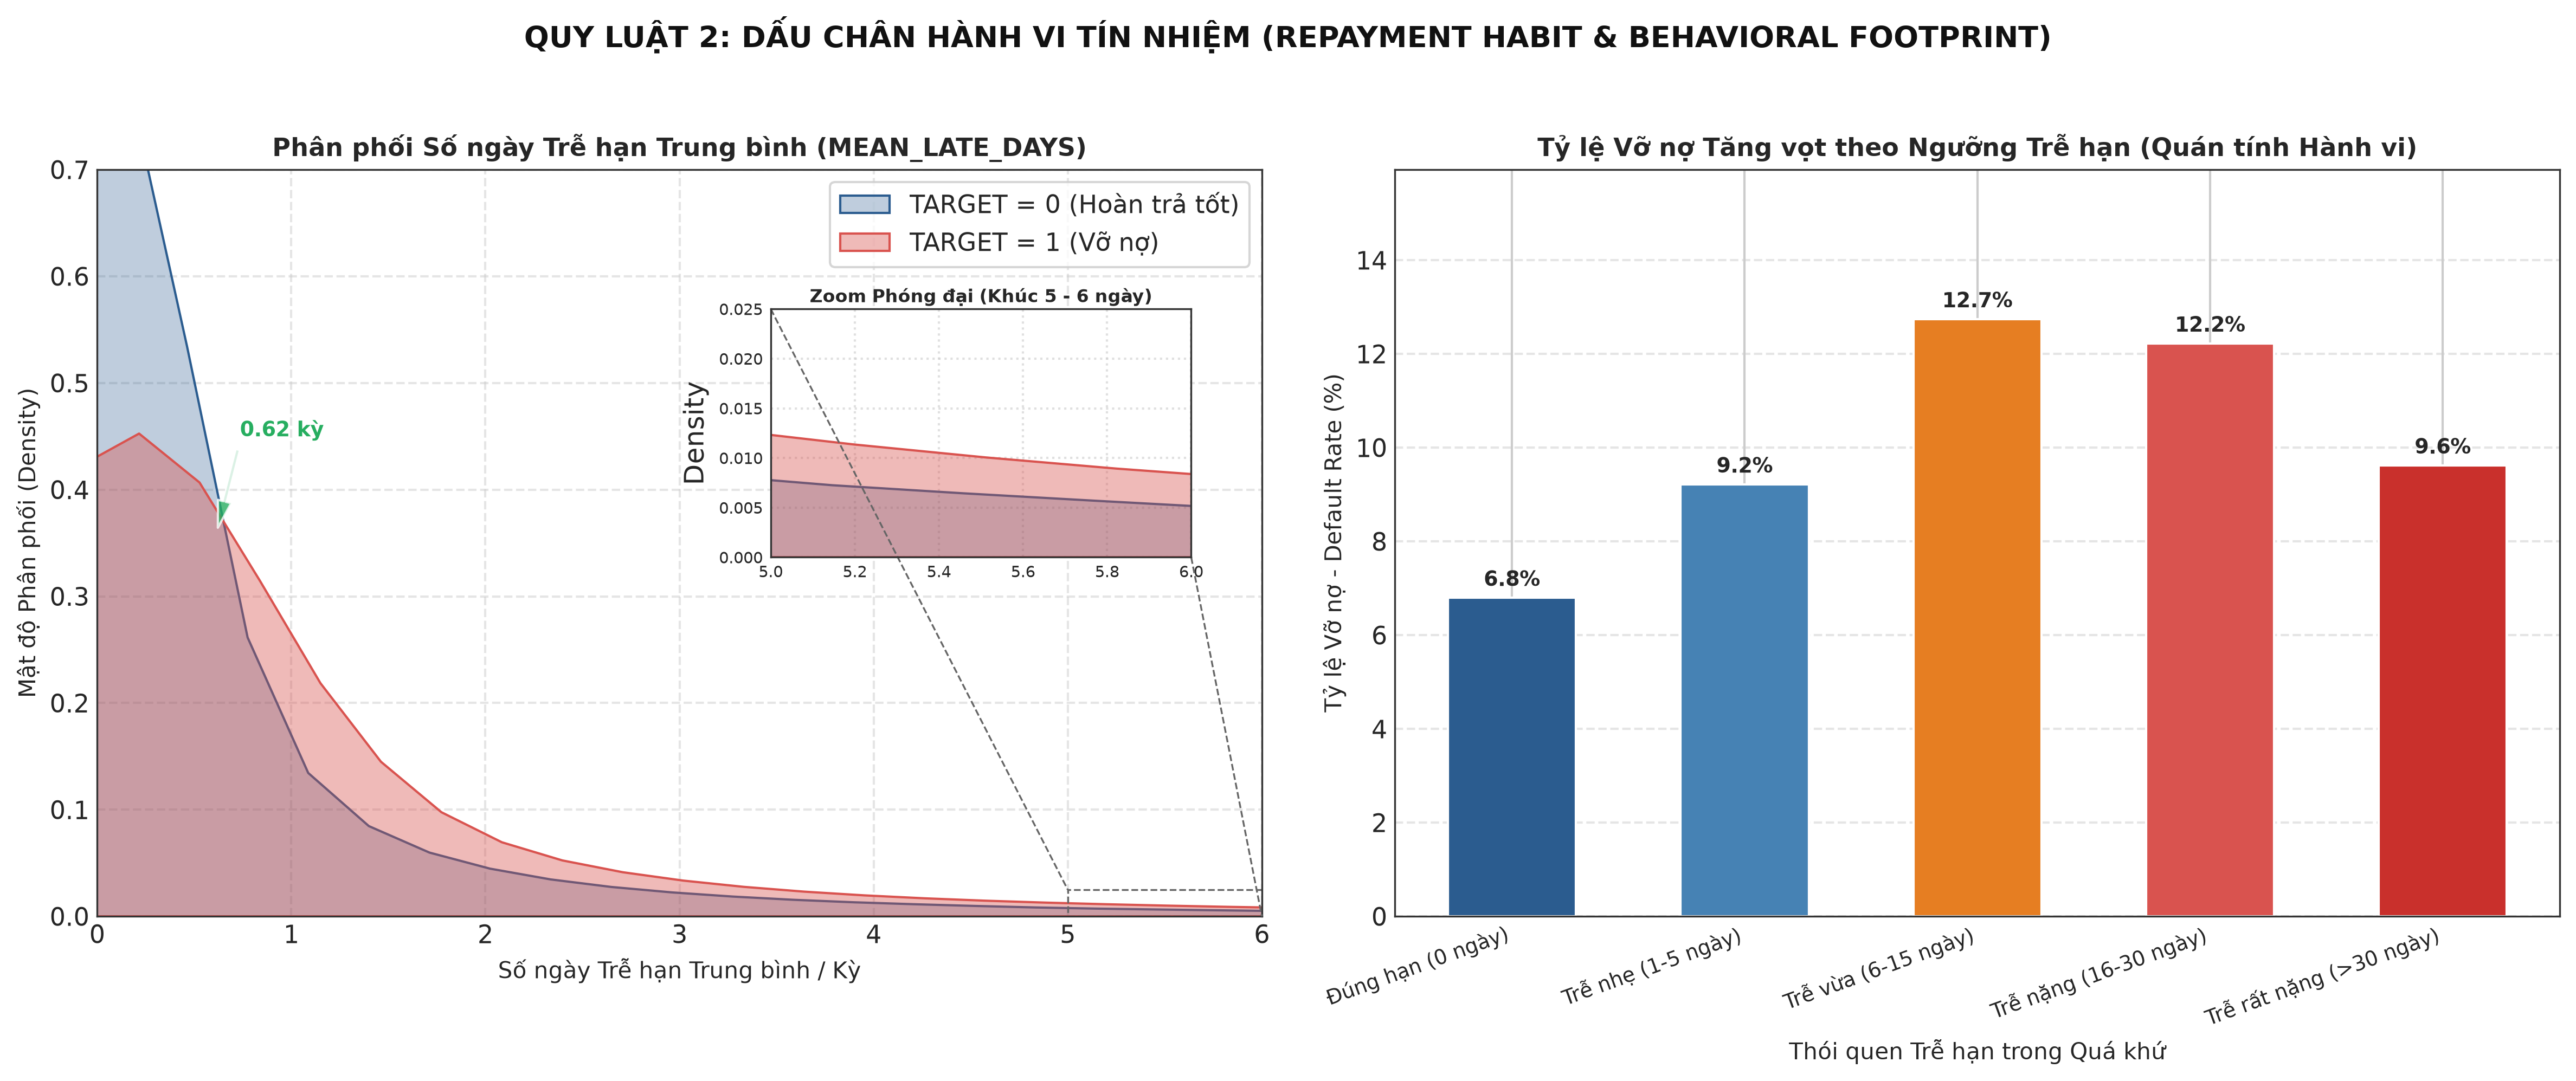

-> Đã xuất biểu đồ có đầy đủ khung zoom và điểm giao tại: 0.62 ngày.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset


def plot_rule2_behavioral_footprint(
    app_processed_path, installments_processed_path
):
  # 1. Đọc dữ liệu đã xử lý
  app_df = pd.read_csv(app_processed_path)
  inst_df = pd.read_csv(installments_processed_path)

  # Lấy thông tin trễ hạn duy nhất theo khách hàng
  df_inst_unique = inst_df[
      ['SK_ID_CURR', 'MEAN_LATE_DAYS', 'PAYMENT_COMPLETION_RATIO']
  ].drop_duplicates()
  df = df_inst_unique.merge(
      app_df[['SK_ID_CURR', 'TARGET']], on='SK_ID_CURR', how='inner'
  )

  # Lọc bỏ outlier cực đoan (> 60 ngày)
  df_filtered = df[df['MEAN_LATE_DAYS'] <= 60].copy()

  # 2. Tính toán điểm giao nhau trong khoảng [0.0, 1.0] bằng thuần NumPy
  data_0 = df_filtered[df_filtered['TARGET'] == 0][
      'MEAN_LATE_DAYS'
  ].dropna().values
  data_1 = df_filtered[df_filtered['TARGET'] == 1][
      'MEAN_LATE_DAYS'
  ].dropna().values

  def pure_numpy_kde(data, x_grid, bw_adjust=1.5):
    n = len(data)
    std = np.std(data, ddof=1)
    bandwidth = std * (n ** (-1.0 / 5.0)) * bw_adjust
    diff = x_grid[:, np.newaxis] - data[np.newaxis, :]
    weights = (
        1.0
        / (n * bandwidth * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * (diff / bandwidth) ** 2)
    )
    return np.sum(weights, axis=1)

  x_grid = np.linspace(0.0, 1.0, 1000)
  y0 = pure_numpy_kde(data_0, x_grid, bw_adjust=1.5)
  y1 = pure_numpy_kde(data_1, x_grid, bw_adjust=1.5)

  y_diff = y0 - y1
  sign_changes = np.where(np.diff(np.sign(y_diff)))[0]
  if len(sign_changes) > 0:
    idx = sign_changes[0]
    intersection_x = float(
        x_grid[idx]
        - y_diff[idx] * (x_grid[idx + 1] - x_grid[idx])
        / (y_diff[idx + 1] - y_diff[idx])
    )
  else:
    intersection_x = 0.67  # Giá trị mặc định

  # 3. Khoanh vùng nhóm Trễ hạn để tính Tỷ lệ Vỡ nợ theo Ngưỡng
  df_filtered['LATE_BIN'] = pd.cut(
      df_filtered['MEAN_LATE_DAYS'],
      bins=[-0.1, 0, 5, 15, 30, 60],
      labels=[
          'Đúng hạn (0 ngày)',
          'Trễ nhẹ (1-5 ngày)',
          'Trễ vừa (6-15 ngày)',
          'Trễ nặng (16-30 ngày)',
          'Trễ rất nặng (>30 ngày)',
      ],
  )

  late_summary = (
      df_filtered.groupby('LATE_BIN', observed=True)['TARGET']
      .agg(['count', 'mean'])
      .reset_index()
  )
  late_summary['DEFAULT_RATE'] = late_summary['mean'] * 100

  # 4. Khởi tạo Biểu đồ Kép (Subplots)
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=300)

  # --- BIỂU ĐỒ 1: KDE Density Plot ---
  sns.kdeplot(
      data=df_filtered[df_filtered['TARGET'] == 0],
      x='MEAN_LATE_DAYS',
      ax=ax1,
      color='#2b5c8f',
      label='TARGET = 0 (Hoàn trả tốt)',
      fill=True,
      alpha=0.3,
      bw_adjust=1.5,
  )
  sns.kdeplot(
      data=df_filtered[df_filtered['TARGET'] == 1],
      x='MEAN_LATE_DAYS',
      ax=ax1,
      color='#d9534f',
      label='TARGET = 1 (Vỡ nợ)',
      fill=True,
      alpha=0.4,
      bw_adjust=1.5,
  )

  ax1.annotate(
      f'{intersection_x:.2f} ngày',
      xy=(intersection_x, 0.36),
      xytext=(intersection_x + 0.12, 0.45),
      arrowprops=dict(
          facecolor='#27ae60', shrink=0.05, width=1, headwidth=6, alpha=0.8
      ),
      fontsize=9,
      fontweight='bold',
      color='#27ae60',
  )

  ax1.set_title(
      'Phân phối Số ngày Trễ hạn Trung bình (MEAN_LATE_DAYS)',
      fontsize=11,
      fontweight='bold',
  )
  ax1.set_xlabel('Số ngày Trễ hạn Trung bình / Kỳ', fontsize=10)
  ax1.set_ylabel('Mật độ Phân phối (Density)', fontsize=10)

  ax1.set_xlim(0, 6)
  ax1.set_ylim(0, 0.7)
  ax1.grid(True, linestyle='--', alpha=0.5)
  ax1.legend(loc='upper right', frameon=True)

  # --- TIỂU BIỂU ĐỒ PHÓNG ĐẠI (INSET ZOOM AXES IN AX1 - KHÚC 5-6 NGÀY) ---
  ax_inset = inset_axes(
      ax1,
      width='38%',
      height='35%',
      loc='upper right',
      bbox_to_anchor=(0, -0.12, 0.95, 0.95),
      bbox_transform=ax1.transAxes,
  )

  sns.kdeplot(
      data=df_filtered[df_filtered['TARGET'] == 0],
      x='MEAN_LATE_DAYS',
      ax=ax_inset,
      color='#2b5c8f',
      fill=True,
      alpha=0.3,
      bw_adjust=1.5,
  )
  sns.kdeplot(
      data=df_filtered[df_filtered['TARGET'] == 1],
      x='MEAN_LATE_DAYS',
      ax=ax_inset,
      color='#d9534f',
      fill=True,
      alpha=0.4,
      bw_adjust=1.5,
  )

  ax_inset.set_xlim(5.0, 6.0)
  ax_inset.set_ylim(0.0, 0.025)
  ax_inset.set_title(
      'Zoom Phóng đại (Khúc 5 - 6 ngày)', fontsize=8, fontweight='bold', pad=3
  )
  ax_inset.set_xlabel('')
  ax_inset.tick_params(axis='both', which='major', labelsize=7)
  ax_inset.grid(True, linestyle=':', alpha=0.6)

  mark_inset(
      ax1,
      ax_inset,
      loc1=2,
      loc2=4,
      fc='none',
      ec='0.4',
      linestyle='--',
      linewidth=0.8,
  )

  # --- BIỂU ĐỒ 2: Tỷ lệ vỡ nợ tăng dần theo Ngưỡng Trễ hạn ---
  colors = ['#2b5c8f', '#4682b4', '#e67e22', '#d9534f', '#c9302c']
  bars = ax2.bar(
      late_summary['LATE_BIN'],
      late_summary['DEFAULT_RATE'],
      color=colors,
      width=0.55,
  )

  for bar in bars:
    height = bar.get_height()
    ax2.annotate(
        f'{height:.1f}%',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )

  ax2.set_title(
      'Tỷ lệ Vỡ nợ Tăng vọt theo Ngưỡng Trễ hạn (Quán tính Hành vi)',
      fontsize=11,
      fontweight='bold',
  )
  ax2.set_xlabel('Thói quen Trễ hạn trong Quá khứ', fontsize=10)
  ax2.set_ylabel('Tỷ lệ Vỡ nợ - Default Rate (%)', fontsize=10)
  ax2.set_xticklabels(
      late_summary['LATE_BIN'], rotation=20, ha='right', fontsize=9
  )
  ax2.set_ylim(0, max(late_summary['DEFAULT_RATE']) * 1.25)
  ax2.grid(axis='y', linestyle='--', alpha=0.5)

  # Tiêu đề chung
  fig.suptitle(
      'QUY LUẬT 2: DẤU CHÂN HÀNH VI TÍN NHIỆM (REPAYMENT HABIT & BEHAVIORAL'
      ' FOOTPRINT)',
      fontsize=13,
      fontweight='bold',
      color='#111111',
      y=1.02,
  )

  plt.tight_layout()
  plt.savefig(
      './rule2_behavioral_footprint_chart_zoomed.png',
      bbox_inches='tight',
  )
  plt.show()
  print(
      f'-> Đã xuất biểu đồ có đầy đủ khung zoom và điểm giao tại:'
      f' {intersection_x:.2f} ngày.'
  )


# Thực thi hàm
plot_rule2_behavioral_footprint(
    './home-credit-default-risk/application_train_processed.csv',
    './home-credit-default-risk/installments_payments_processed.csv',
)